In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [6]:
# import libraries
!pip install -q statsmodels plotly scikit-learn
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px

from IPython.display import display, HTML
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [7]:
# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)
df.columns = ["Month", "Passengers"]

df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").set_index("Month")
df = df.asfreq("MS")

print("Dataset shape:", df.shape)
print("Missing values:", df["Passengers"].isna().sum())
display(df.head())
display(df.describe())

Dataset shape: (144, 1)
Missing values: 0


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [12]:
# Explore the data

fig=px.line(
    df.reset_index(),
    x="Month",
    y="Passengers",
    title="Monthly Airline Passenger Trends (1949-1960)",
    markers=True
)
fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Passengers (thousands)",
    template="plotly_white"
)
fig.show()

df["Rolling_Mean"]=df["Passengers"].rolling(12).mean()
df["Rolling_Std"]=df["Passengers"].rolling(12).std()
fig=go.Figure()
fig.add_trace(go.Scatter(
    x=df.index, y=df["Passengers"],
    name="Actual Passengers"
))
fig.add_trace(go.Scatter(
    x=df.index, y=df["Rolling_Mean"],
    name="12-Month Rolling Mean"
))
fig.add_trace(go.Scatter(
    x=df.index, y=df["Rolling_Std"],
    name="12-Month Rolling Standard Deviation",
    yaxis="y2"
))

fig.update_layout(
    title="Trend and Rolling Statistics",
    template="plotly_white",
    yaxis=dict(title="Passengers (thousands)"),
    yaxis2=dict(title="Rolling Standard Deviation", overlaying="y", side="right")
)

fig.show()

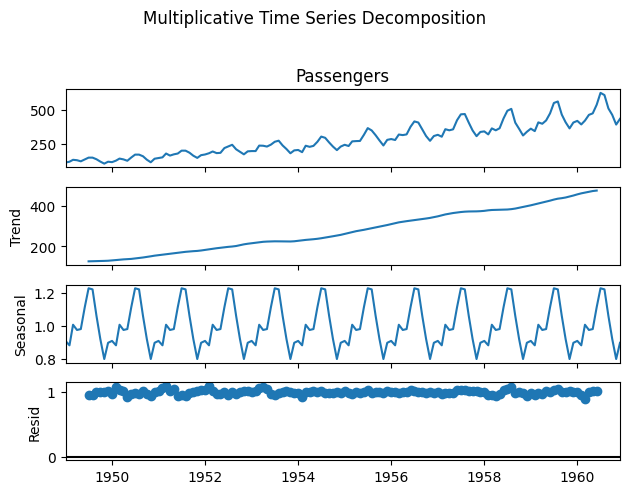

In [13]:
# Decompose the time series
decomposition = seasonal_decompose(
    df["Passengers"],
    model="multiplicative",
    period=12
)

decomposition.plot()
plt.suptitle("Multiplicative Time Series Decomposition", y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Check stationarity
adf_result = adfuller(df["Passengers"].dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("Reject the unit-root null at the 5% level.")
else:
    print("Do not reject the unit-root null at the 5% level.")

log_series = np.log(df["Passengers"])

adf_log = adfuller(log_series.dropna())

print("Log-series ADF Statistic:", adf_log[0])
print("Log-series p-value:", adf_log[1])

ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641
Do not reject the unit-root null at the 5% level.
Log-series ADF Statistic: -1.7170170891069683
Log-series p-value: 0.4223667747703874


In [16]:
# Split the data without shuffling
train = df["Passengers"].iloc[:-12]
test = df["Passengers"].iloc[-12:]

train_log = np.log(train)
test_log = np.log(test)

print("Training period:", train.index.min().date(), "to", train.index.max().date())
print("Testing period:", test.index.min().date(), "to", test.index.max().date())
print("Training observations:", len(train))
print("Testing observations:", len(test))

Training period: 1949-01-01 to 1959-12-01
Testing period: 1960-01-01 to 1960-12-01
Training observations: 132
Testing observations: 12


In [18]:
# Build the ARIMA Model
arima_model=SARIMAX(
    train_log,
    order=(2,1,2),
    seasonal_order=(0,0,0,0),
    enforce_stationarity=False,
    enforce_invertibility=False
)
arima_fit=arima_model.fit(disp=False)
arima_log_forecast=arima_fit.get_forecast(
    steps=len(test)
).predicted_mean
arima_pred=np.exp(arima_log_forecast)
arima_pred.index=test.index
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  132
Model:               SARIMAX(2, 1, 2)   Log Likelihood                 114.354
Date:                Sat, 24 Oct 2026   AIC                           -218.707
Time:                        13:56:26   BIC                           -204.447
Sample:                    01-01-1949   HQIC                          -212.913
                         - 12-01-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2059      0.169      1.216      0.224      -0.126       0.538
ar.L2          0.2838      0.192      1.477      0.140      -0.093       0.660
ma.L1         -0.0611      0.118     -0.517      0.6

In [23]:
#  Build the SARIMA Model
sarima_model = SARIMAX(
    train_log,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_log_forecast = sarima_fit.get_forecast(
    steps=len(test)
).predicted_mean

sarima_pred = np.exp(sarima_log_forecast)
sarima_pred.index = test.index

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  132
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 196.914
Date:                            Sat, 24 Oct 2026   AIC                           -383.829
Time:                                    14:04:55   BIC                           -370.559
Sample:                                01-01-1949   HQIC                          -378.451
                                     - 12-01-1959                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0935      0.235      0.397      0.691      -0.367       0.554
ma.L1         -0.4990      0.213   

In [27]:
# Evaluate both models
results=[]

for model_name, predictions in [
    ("ARIMA",arima_pred),
    ("SARIMA",sarima_pred)
]:
    mae=mean_absolute_error(test, predictions)
    rmse=np.sqrt(mean_squared_error(test, predictions))
    results.append({
        "Model":model_name,
        "MAE":mae,
        "RMSE":rmse
    })
metrics_df=pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics_df.round(3))

# Actual VS Predicted chart
comparison=pd.DataFrame({
    "Actual":test,
    "ARIMA":arima_pred,
    "SARIMA":sarima_pred
})
fig=go.Figure()
fig.add_trace(go.Scatter(
    x=comparison.index,
    y=comparison["Actual"],
    name="Actual",
    mode="lines+markers"
))
fig.add_trace(go.Scatter(
    x=comparison.index,
    y=comparison["ARIMA"],
    name="ARIMA Forecast",
    mode="lines+markers"
))
fig.add_trace(go.Scatter(
    x=comparison.index,
    y=comparison["SARIMA"],
    name="SARIMA Forecast",
    mode="lines+markers"
))

fig.update_layout(
    title="Test Period: Actual vs ARIMA vs SARIMA",
    xaxis_title="Month",
    yaxis_title="Passengers (thousands)",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

,Model,MAE,RMSE
0,SARIMA,10.865,14.754
1,ARIMA,67.863,93.673


In [28]:
# Compare model errors visually
fig = px.bar(
    metrics_df.melt(
        id_vars="Model",
        value_vars=["MAE", "RMSE"],
        var_name="Metric",
        value_name="Error"
    ),
    x="Model",
    y="Error",
    color="Metric",
    barmode="group",
    title="ARIMA vs SARIMA: Forecast Error Comparison",
    template="plotly_white"
)

fig.show()

In [29]:
# Forecast the next 12 months
full_log = np.log(df["Passengers"])

final_arima = SARIMAX(
    full_log,
    order=(2, 1, 2),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

final_sarima = SARIMAX(
    full_log,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

steps = 12

future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=steps,
    freq="MS"
)

arima_future_log = final_arima.get_forecast(steps=steps).predicted_mean
sarima_future_result = final_sarima.get_forecast(steps=steps)

sarima_future_log = sarima_future_result.predicted_mean
sarima_ci_log = sarima_future_result.conf_int()

future_forecast = pd.DataFrame({
    "Month": future_dates,
    "ARIMA_Forecast": np.exp(arima_future_log.to_numpy()),
    "SARIMA_Forecast": np.exp(sarima_future_log.to_numpy()),
    "SARIMA_Lower_95": np.exp(sarima_ci_log.iloc[:, 0].to_numpy()),
    "SARIMA_Upper_95": np.exp(sarima_ci_log.iloc[:, 1].to_numpy())
})

display(future_forecast.round(2))

,Month,ARIMA_Forecast,SARIMA_Forecast,SARIMA_Lower_95,SARIMA_Upper_95
0,1961-01-01,436.56,452.59,420.71,486.89
1,1961-02-01,455.76,427.14,393.02,464.22
2,1961-03-01,485.08,483.01,441.02,528.99
3,1961-04-01,517.13,495.40,449.19,546.35
4,1961-05-01,542.80,515.92,464.78,572.69
5,1961-06-01,554.24,586.94,525.54,655.51
6,1961-07-01,548.29,678.68,604.17,762.36
7,1961-08-01,527.92,678.87,601.03,766.80
8,1961-09-01,500.50,564.05,496.74,640.47
9,1961-10-01,474.30,502.85,440.61,573.87


In [30]:
# Future Forecast chart
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=df.index,
    y=df["Passengers"],
    name="Historical Passengers",
    mode="lines"
))

fig.add_trace(go.Scatter(
    x=future_forecast["Month"],
    y=future_forecast["ARIMA_Forecast"],
    name="ARIMA Forecast",
    mode="lines+markers"
))

fig.add_trace(go.Scatter(
    x=future_forecast["Month"],
    y=future_forecast["SARIMA_Forecast"],
    name="SARIMA Forecast",
    mode="lines+markers"
))

fig.add_trace(go.Scatter(
    x=pd.concat([
        future_forecast["Month"],
        future_forecast["Month"].iloc[::-1]
    ]),
    y=pd.concat([
        future_forecast["SARIMA_Upper_95"],
        future_forecast["SARIMA_Lower_95"].iloc[::-1]
    ]),
    fill="toself",
    fillcolor="rgba(100,100,100,0.15)",
    line=dict(color="rgba(255,255,255,0)"),
    name="SARIMA 95% Interval",
    hoverinfo="skip"
))

fig.update_layout(
    title="Airline Passenger Forecast: Next 12 Months",
    xaxis_title="Month",
    yaxis_title="Passengers (thousands)",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

In [32]:
# Explore charts and project results
import os

output_dir = "/kaggle/working"
os.makedirs(output_dir, exist_ok=True)

# Save data and evaluation outputs
df.to_csv(f"{output_dir}/historical_data.csv")
metrics_df.to_csv(f"{output_dir}/model_comparison.csv", index=False)
comparison.to_csv(f"{output_dir}/test_predictions.csv")
future_forecast.to_csv(f"{output_dir}/future_forecast.csv", index=False)

# Save interactive charts as HTML files
fig.write_html(f"{output_dir}/future_forecast_dashboard.html")

print("Project outputs saved in:", output_dir)
print(os.listdir(output_dir))

Project outputs saved in: /kaggle/working
['.virtual_documents', 'future_forecast.csv', 'test_predictions.csv', 'future_forecast_dashboard.html', 'historical_data.csv', 'model_comparison.csv']


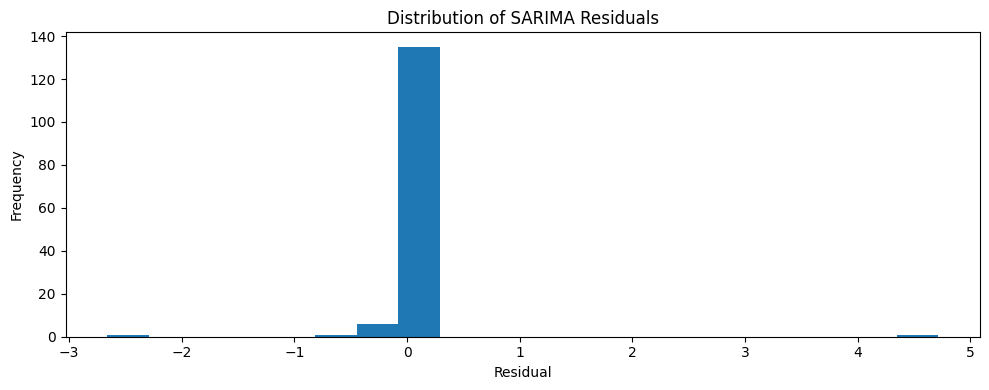

In [33]:
# residual diagnostics
residuals = final_sarima.resid

fig = px.line(
    x=residuals.index,
    y=residuals,
    title="SARIMA Model Residuals",
    labels={"x": "Month", "y": "Residual"}
)
fig.update_layout(template="plotly_white")
fig.show()

plt.figure(figsize=(10, 4))
plt.hist(residuals.dropna(), bins=20)
plt.title("Distribution of SARIMA Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [36]:

print("df exists:", "df" in globals())
print("metrics_df exists:", "metrics_df" in globals())
print("comparison exists:", "comparison" in globals())
print("future_forecast exists:", "future_forecast" in globals())


df exists: True
metrics_df exists: True
comparison exists: True
future_forecast exists: True


In [37]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML

# 1. Prepare historical data
history = df.copy()

if "Passengers" not in history.columns:
    history = history.reset_index()
    history.columns = ["Month", "Passengers"]
else:
    history = history.reset_index()
    history = history.rename(columns={history.columns[0]: "Month"})

history["Month"] = pd.to_datetime(history["Month"])

# 2. Prepare comparison data
test_data = comparison.copy().reset_index()
test_data = test_data.rename(columns={test_data.columns[0]: "Month"})

print("Comparison columns:", test_data.columns.tolist())
print("Metric columns:", metrics_df.columns.tolist())
print("Forecast columns:", future_forecast.columns.tolist())

# 3. Prepare future forecasts
future = future_forecast.copy()

if "Month" not in future.columns:
    future = future.reset_index()
    future = future.rename(columns={future.columns[0]: "Month"})

future["Month"] = pd.to_datetime(future["Month"])

# 4. Find metric values
model_col = "Model"
rmse_col = "RMSE"
mae_col = "MAE"

best_row = metrics_df.loc[metrics_df[rmse_col].idxmin()]
best_model = best_row[model_col]
best_rmse = best_row[rmse_col]
best_mae = best_row[mae_col]

# 5. Dashboard heading
display(HTML("""
<div style="background:#17365D;color:white;padding:22px;
border-radius:10px;font-family:Arial;">
<h1>Airline Passenger Forecasting Dashboard</h1>
<p>ARIMA and SARIMA | Historical Analysis and Future Forecast</p>
</div>
"""))

# 6. KPI cards
display(HTML(f"""
<div style="display:flex;flex-wrap:wrap;gap:12px;margin:15px 0;
font-family:Arial;">
<div style="background:#e8f1fc;padding:18px;border-radius:10px;flex:1;min-width:150px;">
<b>Total Observations</b><h2>{len(history)}</h2>
</div>
<div style="background:#e5f5e9;padding:18px;border-radius:10px;flex:1;min-width:150px;">
<b>Latest Passenger Count</b><h2>{history['Passengers'].iloc[-1]:.0f} thousand</h2>
</div>
<div style="background:#fff3d6;padding:18px;border-radius:10px;flex:1;min-width:150px;">
<b>Lowest Test RMSE</b><h2>{best_model}</h2>
</div>
<div style="background:#f0e7fb;padding:18px;border-radius:10px;flex:1;min-width:150px;">
<b>Test RMSE</b><h2>{best_rmse:.3f}</h2>
</div>
</div>
"""))

# 7. Historical trend chart
fig1 = px.line(
    history,
    x="Month",
    y="Passengers",
    title="1. Historical Monthly Passenger Trend",
    template="plotly_white"
)
fig1.update_layout(yaxis_title="Passengers (thousands)")
fig1.show()

# 8. Actual vs predicted chart
fig2 = go.Figure()

for col in test_data.columns:
    if col != "Month":
        fig2.add_trace(go.Scatter(
            x=test_data["Month"],
            y=test_data[col],
            mode="lines+markers",
            name=str(col)
        ))

fig2.update_layout(
    title="2. Actual vs Predicted (Test Period)",
    xaxis_title="Month",
    yaxis_title="Passengers (thousands)",
    template="plotly_white",
    hovermode="x unified"
)
fig2.show()

# 9. Model comparison chart
metric_chart = px.bar(
    metrics_df,
    x="Model",
    y=["MAE", "RMSE"],
    barmode="group",
    title="3. ARIMA vs SARIMA Model Performance",
    template="plotly_white"
)
metric_chart.show()

# 10. Future forecast chart
fig4 = go.Figure()

fig4.add_trace(go.Scatter(
    x=history["Month"],
    y=history["Passengers"],
    name="Historical",
    mode="lines"
))

for col in ["ARIMA_Forecast", "SARIMA_Forecast"]:
    if col in future.columns:
        fig4.add_trace(go.Scatter(
            x=future["Month"],
            y=future[col],
            name=col.replace("_", " "),
            mode="lines+markers"
        ))

if "SARIMA_Lower_95" in future.columns and "SARIMA_Upper_95" in future.columns:
    fig4.add_trace(go.Scatter(
        x=pd.concat([future["Month"], future["Month"].iloc[::-1]]),
        y=pd.concat([
            future["SARIMA_Upper_95"],
            future["SARIMA_Lower_95"].iloc[::-1]
        ]),
        fill="toself",
        fillcolor="rgba(100,100,100,0.15)",
        line=dict(color="rgba(255,255,255,0)"),
        name="SARIMA 95% interval",
        hoverinfo="skip"
    ))

fig4.update_layout(
    title="4. Next 12 Months Passenger Forecast",
    xaxis_title="Month",
    yaxis_title="Passengers (thousands)",
    template="plotly_white",
    hovermode="x unified"
)
fig4.show()

# 11. Forecast and model metrics tables
display(HTML("<h3>5. Future Forecast Values</h3>"))
display(future.round(2))

display(HTML("<h3>6. Model Evaluation Metrics</h3>"))
display(metrics_df.round(3))

print("Dashboard execution completed.")


Comparison columns: ['Month', 'Actual', 'ARIMA', 'SARIMA']
Metric columns: ['Model', 'MAE', 'RMSE']
Forecast columns: ['Month', 'ARIMA_Forecast', 'SARIMA_Forecast', 'SARIMA_Lower_95', 'SARIMA_Upper_95']


,Month,ARIMA_Forecast,SARIMA_Forecast,SARIMA_Lower_95,SARIMA_Upper_95
0,1961-01-01,436.56,452.59,420.71,486.89
1,1961-02-01,455.76,427.14,393.02,464.22
2,1961-03-01,485.08,483.01,441.02,528.99
3,1961-04-01,517.13,495.40,449.19,546.35
4,1961-05-01,542.80,515.92,464.78,572.69
5,1961-06-01,554.24,586.94,525.54,655.51
6,1961-07-01,548.29,678.68,604.17,762.36
7,1961-08-01,527.92,678.87,601.03,766.80
8,1961-09-01,500.50,564.05,496.74,640.47
9,1961-10-01,474.30,502.85,440.61,573.87


,Model,MAE,RMSE
0,SARIMA,10.865,14.754
1,ARIMA,67.863,93.673


Dashboard execution completed.
